In [1]:
!pip -q install kaggle opencv-python-headless scikit-learn seaborn

In [2]:
import os
import zipfile
import getpass
import subprocess
from pathlib import Path

DATA_ROOT = Path("/content/chest_xray")
DATA_DIR = DATA_ROOT / "chest_xray"
ZIP_PATH = Path("/content/chest-xray-pneumonia.zip")

if not (DATA_DIR / "train").exists():
    os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Enter your Kaggle API token: ")

    if not ZIP_PATH.exists():
        subprocess.run(
            [
                "kaggle", "datasets", "download",
                "-d", "paultimothymooney/chest-xray-pneumonia",
                "-p", "/content"
            ],
            check=True
        )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_ROOT)

if not (DATA_DIR / "train").exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR / 'train'}. "
        "Check that the Kaggle dataset downloaded and extracted correctly."
    )

print("Dataset ready:", DATA_DIR)
print("Top-level folders:", sorted(os.listdir(DATA_DIR)))

Enter your Kaggle API token: ··········
Dataset ready: /content/chest_xray/chest_xray
Top-level folders: ['__MACOSX', 'chest_xray', 'test', 'train', 'val']


In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
train_dir = DATA_DIR / "train"
test_dir = DATA_DIR / "test"

for folder in [train_dir, test_dir, DATA_DIR / "val"]:
    print(f"{folder.name}: {sorted(os.listdir(folder))}")

base_train_dataset = datasets.ImageFolder(train_dir)
test_file_dataset = datasets.ImageFolder(test_dir)

class_names = base_train_dataset.classes
class_to_idx = base_train_dataset.class_to_idx
num_classes = len(class_names)

print("\nClasses:", class_names)
print("Class mapping:", class_to_idx)
print("Original training images:", len(base_train_dataset))
print("Test images:", len(test_file_dataset))

assert class_names == test_file_dataset.classes, "Train/test class mappings do not match."
assert num_classes == 2, "This notebook expects two classes."

train: ['NORMAL', 'PNEUMONIA']
test: ['NORMAL', 'PNEUMONIA']
val: ['NORMAL', 'PNEUMONIA']

Classes: ['NORMAL', 'PNEUMONIA']
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Original training images: 5216
Test images: 624


In [5]:
all_indices = np.arange(len(base_train_dataset))
all_labels = np.array(base_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=all_labels
)

print("Training subset:", len(train_indices))
print("Validation subset:", len(val_indices))
print("Test set:", len(test_file_dataset))

def show_class_counts(indices, labels, names, title):
    counts = np.bincount(labels[indices], minlength=len(names))
    print(title)
    for name, count in zip(names, counts):
        print(f"  {name}: {count}")

show_class_counts(train_indices, all_labels, class_names, "Training class counts:")
show_class_counts(val_indices, all_labels, class_names, "\nValidation class counts:")

Training subset: 4433
Validation subset: 783
Test set: 624
Training class counts:
  NORMAL: 1140
  PNEUMONIA: 3293

Validation class counts:
  NORMAL: 201
  PNEUMONIA: 582


In [6]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.97, 1.03)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

train_full_aug = datasets.ImageFolder(train_dir, transform=train_transform)
train_full_eval = datasets.ImageFolder(train_dir, transform=eval_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

train_dataset = Subset(train_full_aug, train_indices.tolist())
val_dataset = Subset(train_full_eval, val_indices.tolist())

print("Transforms configured.")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Transforms configured.
Training images: 4433
Validation images: 783
Test images: 624


In [7]:
NUM_WORKERS = 2
pin_memory = (device.type == "cuda")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


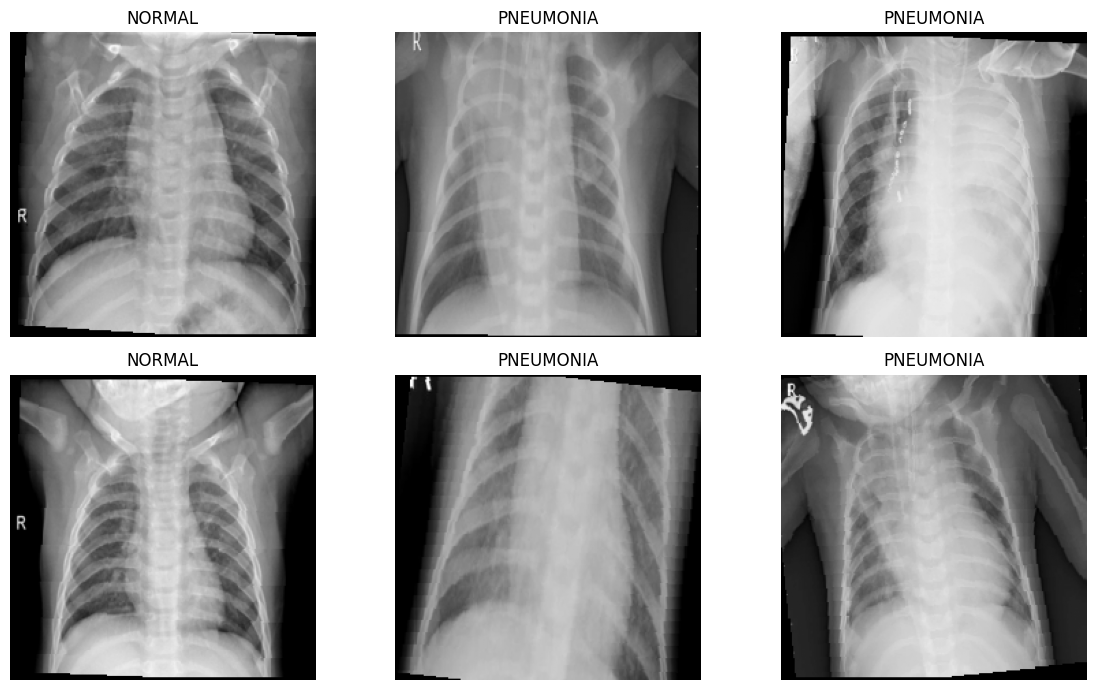

In [8]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 7))
for i in range(min(6, len(images))):
    image = images[i].squeeze(0).cpu().numpy()
    image = np.clip(image * 0.5 + 0.5, 0, 1)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
class CNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 224 -> 112
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2),

            # Block 2: 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2),

            # Block 3: 56 -> 28
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2),

            # Block 4: 28 -> 14
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=False),
            nn.Dropout(p=0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = CNN(num_classes=num_classes).to(device)
print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13): Batch

In [10]:
train_subset_labels = all_labels[train_indices]
train_class_counts = np.bincount(train_subset_labels, minlength=num_classes)

class_weights = len(train_subset_labels) / (
    num_classes * train_class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Training class counts:", dict(zip(class_names, train_class_counts.tolist())))
print("Class weights:", class_weights.detach().cpu().numpy())

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function, optimizer, and scheduler configured.")

Training class counts: {'NORMAL': 1140, 'PNEUMONIA': 3293}
Class weights: [1.9442983  0.67309445]
Loss function, optimizer, and scheduler configured.


In [11]:
EPOCHS = 20
PATIENCE = 5
BEST_MODEL_PATH = "/content/best_chest_xray_cnn.pth"

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * batch_labels.size(0)
        predictions = logits.argmax(dim=1)
        train_correct += (predictions == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_loss = train_loss_total / train_total
    train_accuracy = train_correct / train_total

    # Validation phase
    model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            val_loss_total += loss.item() * batch_labels.size(0)
            predictions = logits.argmax(dim=1)
            val_correct += (predictions == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "class_to_idx": class_to_idx,
                "image_size": IMAGE_SIZE
            },
            BEST_MODEL_PATH
        )
        print("  Saved new best model.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

# Restore the best validation checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nBest model restored. Best validation loss:", round(best_val_loss, 4))

Epoch [01/20] Train Loss: 0.3664 | Train Acc: 83.46% | Val Loss: 0.9427 | Val Acc: 59.51%
  Saved new best model.
Epoch [02/20] Train Loss: 0.2862 | Train Acc: 88.27% | Val Loss: 0.4765 | Val Acc: 87.99%
  Saved new best model.
Epoch [03/20] Train Loss: 0.2564 | Train Acc: 89.76% | Val Loss: 0.1684 | Val Acc: 94.13%
  Saved new best model.
Epoch [04/20] Train Loss: 0.2060 | Train Acc: 91.63% | Val Loss: 0.2150 | Val Acc: 87.99%
Epoch [05/20] Train Loss: 0.1843 | Train Acc: 92.71% | Val Loss: 0.1242 | Val Acc: 94.76%
  Saved new best model.
Epoch [06/20] Train Loss: 0.1630 | Train Acc: 93.55% | Val Loss: 1.1824 | Val Acc: 77.39%
Epoch [07/20] Train Loss: 0.1638 | Train Acc: 93.91% | Val Loss: 0.1026 | Val Acc: 98.21%
  Saved new best model.
Epoch [08/20] Train Loss: 0.1623 | Train Acc: 93.64% | Val Loss: 0.2615 | Val Acc: 83.91%
Epoch [09/20] Train Loss: 0.1431 | Train Acc: 94.47% | Val Loss: 0.0877 | Val Acc: 96.30%
  Saved new best model.
Epoch [10/20] Train Loss: 0.1299 | Train Acc: 

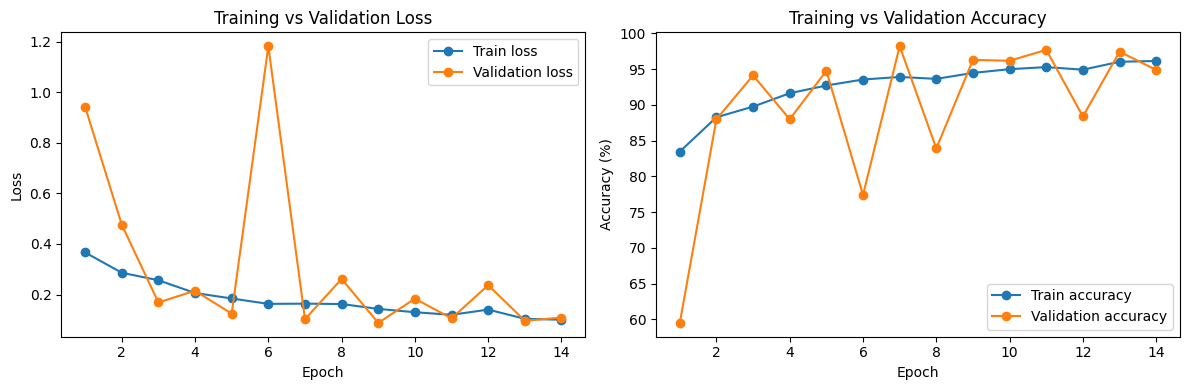

In [12]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs_ran, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, np.array(history["train_accuracy"]) * 100, marker="o", label="Train accuracy")
plt.plot(epochs_ran, np.array(history["val_accuracy"]) * 100, marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)

        logits = model(batch_images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        y_true.extend(batch_labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

test_accuracy = accuracy_score(y_true, y_pred)

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Final Test Accuracy: 83.65%

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9342    0.6068    0.7358       234
   PNEUMONIA     0.8051    0.9744    0.8817       390

    accuracy                         0.8365       624
   macro avg     0.8696    0.7906    0.8087       624
weighted avg     0.8535    0.8365    0.8270       624



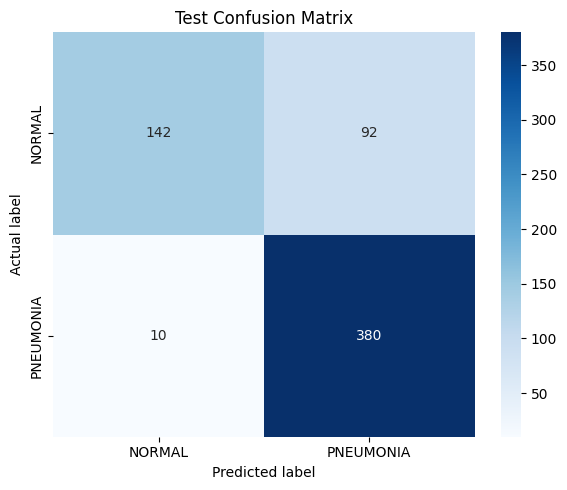

Confusion matrix (rows=actual, columns=predicted):
[[142  92]
 [ 10 380]]


In [14]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows=actual, columns=predicted):")
print(cm)

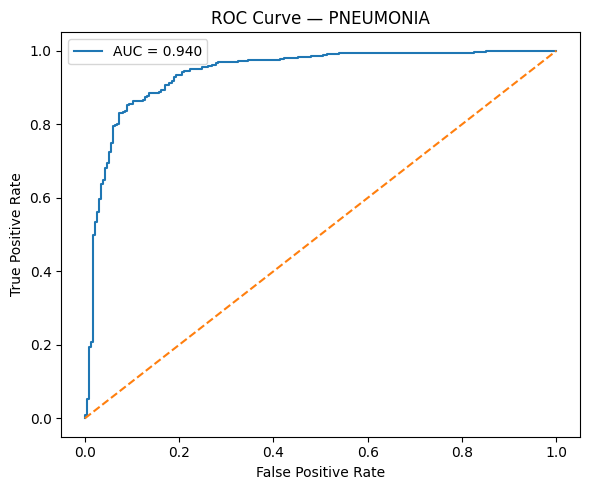

ROC-AUC: 0.9400


In [15]:
pneumonia_index = class_to_idx.get("PNEUMONIA")

if pneumonia_index is not None and len(np.unique(y_true)) == 2:
    binary_true = (y_true == pneumonia_index).astype(int)
    pneumonia_prob = y_prob[:, pneumonia_index]

    auc_score = roc_auc_score(binary_true, pneumonia_prob)
    fpr, tpr, thresholds = roc_curve(binary_true, pneumonia_prob)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — PNEUMONIA")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"ROC-AUC: {auc_score:.4f}")
else:
    print("ROC-AUC could not be calculated: both classes are required.")

In [16]:
FINAL_MODEL_PATH = "/content/chest_xray_cnn_final.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "class_to_idx": class_to_idx,
        "image_size": IMAGE_SIZE
    },
    FINAL_MODEL_PATH
)

print("Final model saved to:", FINAL_MODEL_PATH)

Final model saved to: /content/chest_xray_cnn_final.pth


In [17]:
def predict_xray(image_path, trained_model=model):
    image = Image.open(image_path).convert("L")
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    trained_model.eval()
    with torch.no_grad():
        logits = trained_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        predicted_index = int(probabilities.argmax().item())

    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index].item())

    plt.figure(figsize=(5, 5))
    plt.imshow(image.resize((IMAGE_SIZE, IMAGE_SIZE)), cmap="gray")
    plt.title(f"Prediction: {predicted_class}\nModel score: {confidence:.2%}")
    plt.axis("off")
    plt.show()

    return predicted_class, confidence

# Example:
# IMAGE_PATH = "/content/example_xray.jpeg"
# prediction, score = predict_xray(IMAGE_PATH)
# print("Predicted class:", prediction)
# print("Model score:", f"{score:.2%}")

In [18]:
def make_gradcam(image_path, trained_model=model, target_class=None):
    trained_model.eval()

    original = Image.open(image_path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    input_tensor = eval_transform(Image.open(image_path).convert("L")).unsqueeze(0).to(device)

    activations = {}
    gradients = {}
    target_layer = trained_model.features[14]

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    trained_model.zero_grad(set_to_none=True)
    logits = trained_model(input_tensor)

    predicted_index = int(logits.argmax(dim=1).item())
    class_index = predicted_index if target_class is None else int(target_class)

    score = logits[:, class_index]
    score.backward()

    feature_maps = activations["value"].detach()
    grads = gradients["value"].detach()

    channel_weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (channel_weights * feature_maps).sum(dim=1, keepdim=True)
    cam = torch.relu(cam)
    cam = torch.nn.functional.interpolate(
        cam,
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].cpu().numpy()
    cam = cam - cam.min()
    if cam.max() > 0:
        cam = cam / cam.max()

    forward_handle.remove()
    backward_handle.remove()
    trained_model.zero_grad(set_to_none=True)

    gray = np.array(original)
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    original_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(original_rgb, 0.60, heatmap, 0.40, 0)

    print("Predicted class:", class_names[predicted_index])
    print("Grad-CAM target class:", class_names[class_index])

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(gray, cmap="gray")
    plt.title("Original X-ray")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet")
    plt.title("Grad-CAM heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Grad-CAM overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Example:
# make_gradcam("/content/example_xray.jpeg")

Saving 76052f7902246ff862f52f5d3cd9cd_big_gallery.jpg to 76052f7902246ff862f52f5d3cd9cd_big_gallery.jpg


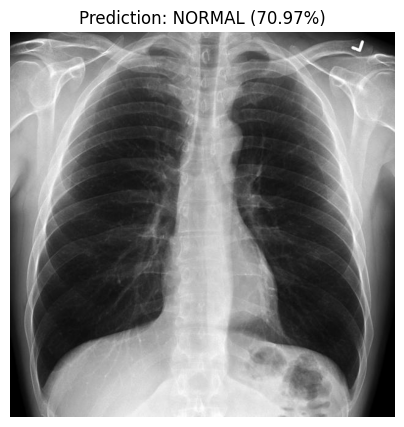

In [19]:
from google.colab import files
import torch.nn.functional as F

def predict_uploaded_xray(model, transform, class_names, device):
    uploaded = files.upload()
    model.eval()

    for filename in uploaded.keys():
        # Open image and apply the same eval_transform used for testing
        img = Image.open(filename).convert("RGB")
        input_tensor = transform(img).unsqueeze(0).to(device)  # Add batch dimension

        with torch.no_grad():
            output = model(input_tensor)
            # Assuming 2 output classes (CrossEntropyLoss):
            probabilities = F.softmax(output, dim=1)[0]
            pred_idx = torch.argmax(probabilities).item()
            confidence = probabilities[pred_idx].item() * 100

        # Display image with prediction
        plt.figure(figsize=(5, 5))
        plt.imshow(img, cmap="gray")
        plt.title(f"Prediction: {class_names[pred_idx]} ({confidence:.2f}%)")
        plt.axis("off")
        plt.show()

# Run the upload and prediction tool
predict_uploaded_xray(model, eval_transform, class_names, device)